In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_score, recall_score, f1_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import warnings
warnings.filterwarnings('ignore')

# 1. Load the Dataset
# Replace 'loan_data.csv' with the actual dataset file name from Kaggle
df = pd.read_csv('loan_prediction.csv')

# Assume 'Loan_Status' is the target variable (1 for Approved, 0 for Rejected)
# Drop identifying columns like 'Loan_ID' if they exist
if 'Loan_ID' in df.columns:
    df.drop('Loan_ID', axis=1, inplace=True)

X = df.drop('Loan_Status', axis=1)
y = df['Loan_Status'].apply(lambda x: 1 if x == 'Y' else 0) # Adjust mapping based on actual data

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Data Preprocessing Setup
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

# Pipeline for numerical features: impute missing with median, then scale
numeric_transformer = ImbPipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline for categorical features: impute missing with mode, then one-hot encode
categorical_transformer = ImbPipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 3. Define Models and Handle Class Imbalance
# Using SMOTE within an imblearn pipeline ensures synthetic data is only created on the training fold
models = {
    "Logistic Regression": ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', LogisticRegression(random_state=42, max_iter=1000))
    ]),
    "Random Forest": ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', RandomForestClassifier(random_state=42, n_estimators=100))
    ])
}

# 4. Train Models and Report Metrics
results = {}

for name, model_pipeline in models.items():
    # Train the model
    model_pipeline.fit(X_train, y_train)

    # Predict probabilities and classes
    y_pred = model_pipeline.predict(X_test)
    y_pred_proba = model_pipeline.predict_proba(X_test)[:, 1]

    # Calculate metrics
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    results[name] = {
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    }

    print(f"--- {name} Performance ---")
    print(classification_report(y_test, y_pred))
    print(f"ROC-AUC: {roc_auc:.4f}\n")

# Display summary comparison
results_df = pd.DataFrame(results).T
print("--- Model Comparison Summary ---")
print(results_df)

--- Logistic Regression Performance ---
              precision    recall  f1-score   support

           0       0.72      0.68      0.70        38
           1       0.86      0.88      0.87        85

    accuracy                           0.82       123
   macro avg       0.79      0.78      0.79       123
weighted avg       0.82      0.82      0.82       123

ROC-AUC: 0.8759

--- Random Forest Performance ---
              precision    recall  f1-score   support

           0       0.72      0.61      0.66        38
           1       0.84      0.89      0.86        85

    accuracy                           0.80       123
   macro avg       0.78      0.75      0.76       123
weighted avg       0.80      0.80      0.80       123

ROC-AUC: 0.7899

--- Model Comparison Summary ---
                     Precision    Recall  F1-Score   ROC-AUC
Logistic Regression   0.862069  0.882353  0.872093  0.875851
Random Forest         0.835165  0.894118  0.863636  0.789938


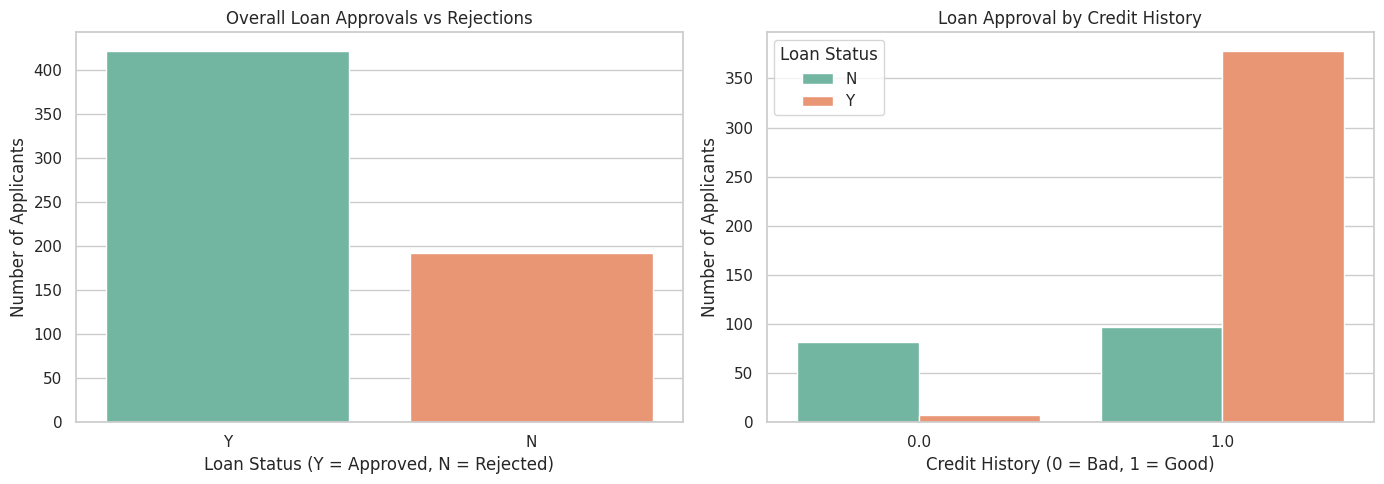

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Overall Loan Approval Status
sns.countplot(x='Loan_Status', data=df, palette='Set2', ax=axes[0])
axes[0].set_title('Overall Loan Approvals vs Rejections')
axes[0].set_xlabel('Loan Status (Y = Approved, N = Rejected)')
axes[0].set_ylabel('Number of Applicants')

# Graph 2: Loan Approval based on Credit History
# (Assuming 'Credit_History' exists in your dataset, which is standard for this Kaggle dataset)
if 'Credit_History' in df.columns:
    sns.countplot(x='Credit_History', hue='Loan_Status', data=df, palette='Set2', ax=axes[1])
    axes[1].set_title('Loan Approval by Credit History')
    axes[1].set_xlabel('Credit History (0 = Bad, 1 = Good)')
    axes[1].set_ylabel('Number of Applicants')
    axes[1].legend(title='Loan Status')
else:
    axes[1].set_visible(False) # Hide if the column isn't found

plt.tight_layout()
plt.show()